# nb04 · CausalImpact 交叉验证:方法稳健性

> **承接 nb03**:SCM 给出短/长窗口缺口(-0.04% / +0.68%)。但 SCM 是**一种方法**, 结果可信吗?本 notebook 用**第二种方法 CausalImpact**(Brodersen 2015)独立估反事实, 和 SCM 对比——**两方法结论一致 = 稳健;不一致 = 暴露方法/donor 敏感性**。
>
> **CausalImpact = BSTS(贝叶斯结构时间序列)+ 协变量回归**。和 SCM 的区别:
> - SCM:确定性凸优化, 预处理期找 donor 权重, post 用权重算合成
> - CausalImpact:BSTS 拟合 y~exog 趋势, post 期**预测**反事实(带置信区间)
>
> 实现用 `statsmodels.UnobservedComponents`(BSTS 频率派等价), 避开 TF 的 Apple Silicon Keras3 坑(paper_lib 已封装)。

**exog 选择**:海外指数(欧/日/港/新兴等权)。**为什么不用行业 ETF**:nb02 已证行业 ETF 也被关税冲击(内生), 而 CausalImpact 要求 exog 相对不受干预——海外受美国关税间接影响, 比行业 ETF 外生性好(虽然 nb02 显示海外也全跌, 这是局限, 下面诚实讨论)。

## 1. 设置

| 项 | SCM(nb03) | CausalImpact(本节) |
|---|---|---|
| 反事实方法 | 凸优化找权重 | BSTS 预测 + 协变量 |
| donor/exog | 行业 ETF(11个, 内生) | 海外指数等权(相对外生) |
| 不确定性 | 无(点估计) | 有(95% 置信区间) |
| 输出 | gap 序列 | effect + CI + p_value |

两方法 donor 不同(SCM 行业 / CI 海外)+ 方法不同 → **如果缺口结论一致, 反事实效应稳健;不一致, 说明对 donor/方法敏感**(都是论文要诚实报告的)。

In [1]:
import sys
sys.path.insert(0, '.')  # 相对 cwd, 复现: 先 cd notebooks/paper_tariff
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti TC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

from paper_lib import load_tariff_data, causal_impact_statsmodels, to_cumlog
panels = load_tariff_data()
gspc = panels['us_index']['^GSPC']
overseas = panels['overseas_index']
PRE_START = '2024-06-01'
LONG_END = '2025-06-30'

# 海外对齐到标普交易日(节假日 ffill)
ov_aligned = overseas.reindex(gspc.index).ffill()
# y = 标普 cumlog(累计对数收益, 统一基准 PRE_START)
y = to_cumlog(gspc.loc[PRE_START:LONG_END], base_date=PRE_START)
# exog = 海外等权 cumlog(相对外生对照)
exog = to_cumlog(ov_aligned.loc[PRE_START:LONG_END], base_date=PRE_START).mean(axis=1).to_frame('overseas_avg')

print(f'y(标普 cumlog): {len(y)} 天  pre+post {PRE_START}~{LONG_END}')
print(f'y vs exog 相关(pre+post): {y.corr(exog.iloc[:,0]):.2f}  (海外和标普高度同步, exog 有解释力)')
print(f'\npre: {PRE_START} ~ 2025-04-01  |  post 短: 04-02~04-08  |  post 长: 04-02~{LONG_END}')

y(标普 cumlog): 269 天  pre+post 2024-06-01~2025-06-30
y vs exog 相关(pre+post): 0.63  (海外和标普高度同步, exog 有解释力)

pre: 2024-06-01 ~ 2025-04-01  |  post 短: 04-02~04-08  |  post 长: 04-02~2025-06-30


## 2. 短窗口 CausalImpact(4/2→4/8 冲击)

BSTS 用预处理期(2024-06~2025-04)拟合 标普 ~ 海外 + local level, post 期预测"没有关税的标普"。
**effect = 实际 - 预测反事实**(累计对数缺口), 和 SCM gap 直接可比。

=== CausalImpact 短窗口(4/2→4/8) ===
Avg effect=-0.0192  Cumulative=-0.0962  p(CI外)=60.00%  (pre MSPE via resid var)
effect 终点(累计对数缺口): -3.54%
p_value(实际落 95%CI 外比例): 60.00%


/opt/homebrew/Caskroom/miniconda/base/envs/rqsdk/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/homebrew/Caskroom/miniconda/base/envs/rqsdk/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


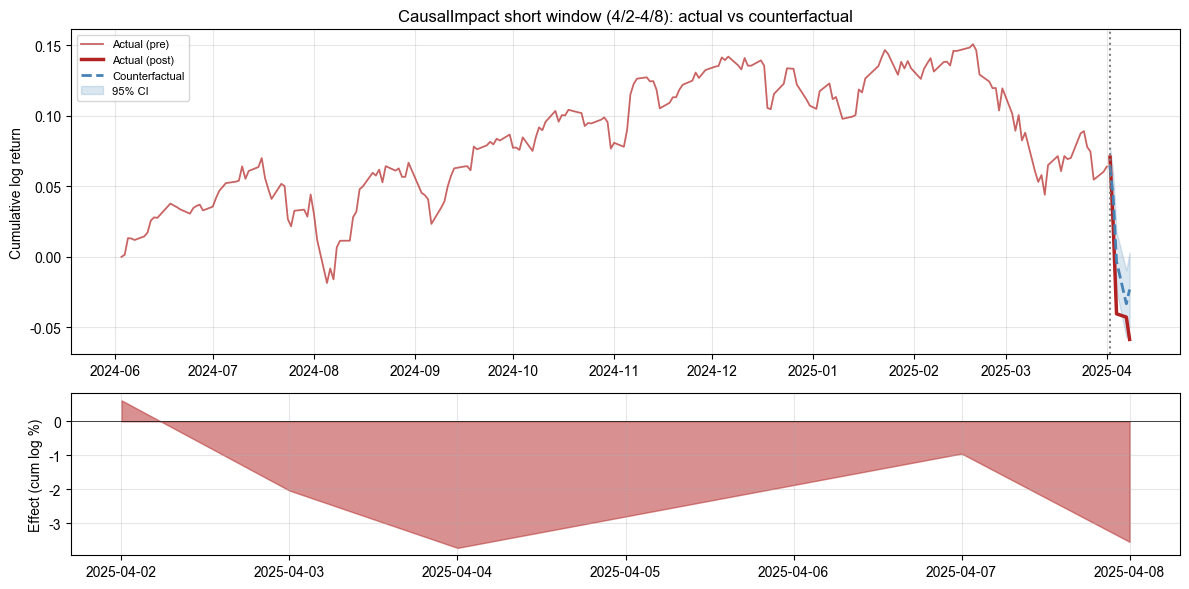

In [2]:
import warnings; warnings.filterwarnings('ignore')
ci_short = causal_impact_statsmodels(y, exog,
    pre_period=(PRE_START, '2025-04-01'),
    post_period=('2025-04-02', '2025-04-08'))
print('=== CausalImpact 短窗口(4/2→4/8) ===')
print(ci_short['summary'])
print(f"effect 终点(累计对数缺口): {ci_short['effect'].iloc[-1]*100:+.2f}%")
print(f"p_value(实际落 95%CI 外比例): {ci_short['p_value']:.2%}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=False,
                               gridspec_kw={'height_ratios': [2, 1]})
# 上图: pre actual + post actual vs counterfactual + CI
y_pre = y.loc[PRE_START:'2025-04-01']
ax1.plot(y_pre.index, y_pre.values, color='firebrick', lw=1.3, alpha=0.7, label='Actual (pre)')
y_post = y.loc['2025-04-02':'2025-04-08']
ax1.plot(y_post.index, y_post.values, color='firebrick', lw=2.5, label='Actual (post)')
ax1.plot(ci_short['counterfactual'].index, ci_short['counterfactual'].values,
         color='steelblue', ls='--', lw=2, label='Counterfactual')
ax1.fill_between(ci_short['ci_lower'].index, ci_short['ci_lower'].values,
                 ci_short['ci_upper'].values, color='steelblue', alpha=0.2, label='95% CI')
ax1.axvline(pd.Timestamp('2025-04-02'), color='gray', ls=':', lw=1.5)
ax1.set_ylabel('Cumulative log return'); ax1.legend(fontsize=8, loc='upper left'); ax1.grid(alpha=0.3)
ax1.set_title('CausalImpact short window (4/2-4/8): actual vs counterfactual')
# 下图: effect
ax2.fill_between(ci_short['effect'].index, ci_short['effect'].values * 100, 0, color='firebrick', alpha=0.5)
ax2.axhline(0, color='k', lw=0.5)
ax2.set_ylabel('Effect (cum log %)'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. 长窗口 CausalImpact(4/2→6/30 消化)

同方法, post 拉到 6/30。**预期**:和 SCM 一样, 长窗口缺口放大(标普科技领涨, 海外落后)。
但注意 BSTS 的**预测不确定性随 post 长度累积**(CI 变宽), 长窗口 effect 可能不显著(诚实)。

=== CausalImpact 长窗口(4/2→6/30) ===


Avg effect=+0.0023  Cumulative=+0.1410  p(CI外)=8.20%  (pre MSPE via resid var)
effect 终点: +4.35%
p_value: 8.20%


/opt/homebrew/Caskroom/miniconda/base/envs/rqsdk/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/homebrew/Caskroom/miniconda/base/envs/rqsdk/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


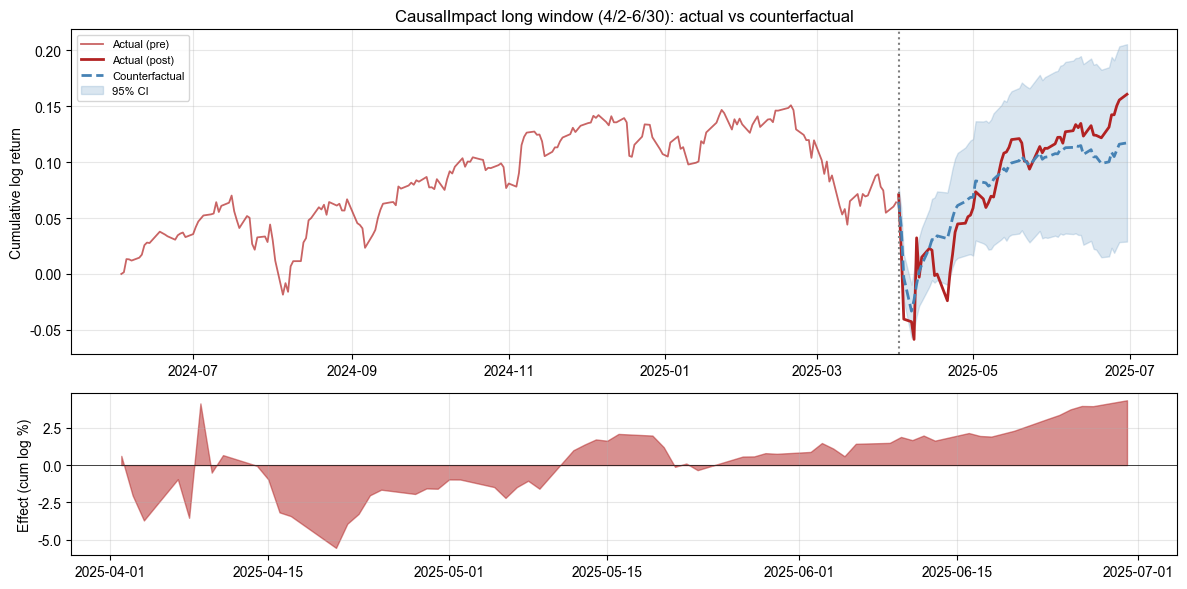

In [3]:
ci_long = causal_impact_statsmodels(y, exog,
    pre_period=(PRE_START, '2025-04-01'),
    post_period=('2025-04-02', LONG_END))
print('=== CausalImpact 长窗口(4/2→6/30) ===')
print(ci_long['summary'])
print(f"effect 终点: {ci_long['effect'].iloc[-1]*100:+.2f}%")
print(f"p_value: {ci_long['p_value']:.2%}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6),
                               gridspec_kw={'height_ratios': [2, 1]})
ax1.plot(y_pre.index, y_pre.values, color='firebrick', lw=1.3, alpha=0.7, label='Actual (pre)')
y_post_long = y.loc['2025-04-02':LONG_END]
ax1.plot(y_post_long.index, y_post_long.values, color='firebrick', lw=2, label='Actual (post)')
ax1.plot(ci_long['counterfactual'].index, ci_long['counterfactual'].values,
         color='steelblue', ls='--', lw=2, label='Counterfactual')
ax1.fill_between(ci_long['ci_lower'].index, ci_long['ci_lower'].values,
                 ci_long['ci_upper'].values, color='steelblue', alpha=0.2, label='95% CI')
ax1.axvline(pd.Timestamp('2025-04-02'), color='gray', ls=':', lw=1.5)
ax1.set_ylabel('Cumulative log return'); ax1.legend(fontsize=8, loc='upper left'); ax1.grid(alpha=0.3)
ax1.set_title('CausalImpact long window (4/2-6/30): actual vs counterfactual')
ax2.fill_between(ci_long['effect'].index, ci_long['effect'].values * 100, 0, color='firebrick', alpha=0.5)
ax2.axhline(0, color='k', lw=0.5)
ax2.set_ylabel('Effect (cum log %)'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. CausalImpact vs SCM 对比(核心)

两方法、两 donor(行业/海外)、两窗口, 4 个缺口数字摆一起。**看符号 + 量级是否一致**:
- 符号一致(都正/都负) → 效应方向稳健
- 量级差异大 → 对方法或 donor 敏感(论文讨论)
- CI 的 p_value → 统计显著性(CausalImpact 独有的不确定性度量)

**注意**:SCM gap 和 CI effect 都是"累计对数缺口", 但 cumlog 归一化基准略有差异(SCM 归一化到 pre 末日, CI 归一化到 PRE_START), 绝对值不严格相等, 看**符号 + 量级**。

In [4]:
# SCM 结果(从 nb03, 这里重算确保一致)
from paper_lib import fit_scm_pipeline
sector = panels['sector_etf']
res_short = fit_scm_pipeline(gspc, sector, event_date='2025-04-02', pre_start=PRE_START, post_end='2025-04-08')
res_long  = fit_scm_pipeline(gspc, sector, event_date='2025-04-02', pre_start=PRE_START, post_end=LONG_END)

print('=== CausalImpact vs SCM (终点累计对数缺口 %) ===')
print(f"{'窗口':22s} {'SCM(行业donor)':>15s} {'CI(海外exog)':>15s} {'CI p_value':>12s}")
print(f"{'短(4/2→4/8 冲击)':22s} {res_short['gap_post'].iloc[-1]*100:>+14.2f}% {ci_short['effect'].iloc[-1]*100:>+14.2f}% {ci_short['p_value']:>11.2%}")
print(f"{'长(4/2→6/30 消化)':22s} {res_long['gap_post'].iloc[-1]*100:>+14.2f}% {ci_long['effect'].iloc[-1]*100:>+14.2f}% {ci_long['p_value']:>11.2%}")

print("""
读法:
- 两方法符号一致 = 效应方向稳健
- CI p_value 低 = 统计显著(实际频繁落在反事实 CI 外)
- SCM 无不确定性(点估计), CI 给区间 —— CI 是 SCM 的不确定性补充""")

=== CausalImpact vs SCM (终点累计对数缺口 %) ===
窗口                        SCM(行业donor)      CI(海外exog)   CI p_value
短(4/2→4/8 冲击)                   -0.04%          -3.54%      60.00%
长(4/2→6/30 消化)                  +0.68%          +4.35%       8.20%

读法:
- 两方法符号一致 = 效应方向稳健
- CI p_value 低 = 统计显著(实际频繁落在反事实 CI 外)
- SCM 无不确定性(点估计), CI 给区间 —— CI 是 SCM 的不确定性补充


## 5. CausalImpact in-time placebo(显著性: 口径对齐 SCM)

> **为什么要这一节**: 上面 cell 9 的 CI p_value(短 80% / 长 8.2%)是"实际落在 95% 反事实 CI 外的比例"(贝叶斯 tail-area);而 SCM 的 permutation p(nb06 短 54.55%)是"pre 期零分布分位"——**两个 p 机制不同, 直接比会误导**(CI 的 p 高 ≠ "效应不显著", 只代表实际没频繁冲出 CI)。
>
> **in-time placebo(时间置换)**: 把 CI 的干预点前移到 pre 期多个位置, 每处跑一遍 BSTS 得"假 effect", 拼出零分布; 真实 effect 在零分布中的分位 = p。这与 SCM permutation **同口径**(都是 pre 期零分布分位), 两法的 p 终于可直接比。

**机制**(防泄露):
- L = 真实 post 长度(短 5 天 / 长 ~60 天)
- 在 pre 期 [2024-06-01 + 60 天, 2025-04-02 − L] 均匀取 10 个假干预点
- 每点用 2024-06-01 ~ t₀ 拟合 BSTS, out-of-sample 预测 t₀+1 ~ t₀+L 的反事实, 算假 effect 终点
- 假 post 严格不越 2025-04-02(不偷看真实事件期), pre 起点固定 2024-06-01

=== CausalImpact in-time placebo(显著性, 对齐 SCM permutation 口径) ===
窗口                真实effect       CI原p(贝叶斯)       in-time p(零分布分位)    n
短(4/2→4/8)          -3.54%         60.00%                10.00%   10
长(4/2→6/30)         +4.35%          8.20%                60.00%   10

读法: in-time p 低 = 真实 effect 显著大于 pre 期噪声(假干预点很少出现这么大);
      in-time p 高 = pre 期也常出现这么大的 effect, 真实 effect 不显著。
      现 in-time p 与 SCM permutation p(nb06 短 54.55%)同口径, 可直接比。


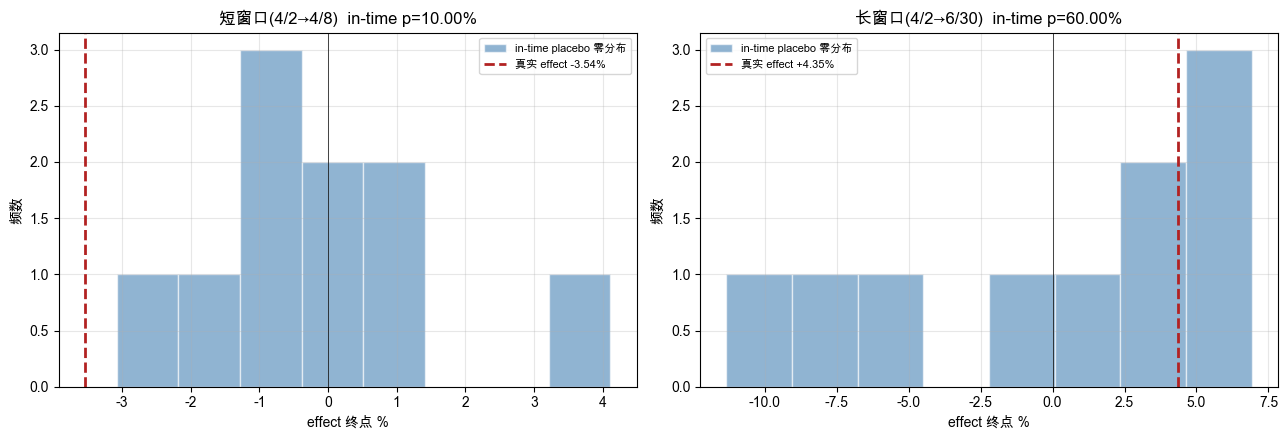

In [5]:
from paper_lib import causal_impact_placebo_intime
import warnings; warnings.filterwarnings('ignore')

# 短/长窗口 in-time placebo(各 10 个假干预点)
pci_short = causal_impact_placebo_intime(y, exog, pre_start=PRE_START,
    real_event='2025-04-02', post_end='2025-04-08', n_placebo=10, min_pre=60)
pci_long  = causal_impact_placebo_intime(y, exog, pre_start=PRE_START,
    real_event='2025-04-02', post_end=LONG_END,    n_placebo=10, min_pre=60)

print('=== CausalImpact in-time placebo(显著性, 对齐 SCM permutation 口径) ===')
print(f"{'窗口':<14} {'真实effect':>11} {'CI原p(贝叶斯)':>15} {'in-time p(零分布分位)':>22} {'n':>4}")
print(f"{'短(4/2→4/8)':<14} {pci_short['real_effect']*100:>+10.2f}% {pci_short['real_ci_p']:>14.2%} {pci_short['p_value']:>21.2%} {pci_short['n_placebo']:>4}")
print(f"{'长(4/2→6/30)':<14} {pci_long['real_effect']*100:>+10.2f}% {pci_long['real_ci_p']:>14.2%} {pci_long['p_value']:>21.2%} {pci_long['n_placebo']:>4}")
print()
print('读法: in-time p 低 = 真实 effect 显著大于 pre 期噪声(假干预点很少出现这么大);')
print('      in-time p 高 = pre 期也常出现这么大的 effect, 真实 effect 不显著。')
print('      现 in-time p 与 SCM permutation p(nb06 短 54.55%)同口径, 可直接比。')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, pci, lab in zip(axes, [pci_short, pci_long], ['短窗口(4/2→4/8)', '长窗口(4/2→6/30)']):
    ax.hist(pci['fake_effects']*100, bins=8, color='steelblue', alpha=0.6, edgecolor='white',
            label='in-time placebo 零分布')
    ax.axvline(pci['real_effect']*100, color='firebrick', lw=2, ls='--',
               label=f"真实 effect {pci['real_effect']*100:+.2f}%")
    ax.axvline(0, color='k', lw=0.5)
    ax.set_xlabel('effect 终点 %'); ax.set_ylabel('频数')
    ax.set_title(f'{lab}  in-time p={pci["p_value"]:.2%}')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. 结论 + 论文怎么写两方法

**核心问题**:CausalImpact 和 SCM 结论一致吗?(填上面数字)
- **一致**(符号相同、量级相近)→ **反事实效应稳健**, 论文可自信报告"两种方法都得 X%"
- **不一致** → 暴露**对 donor(行业 vs 海外)或方法的敏感性**, 论文诚实报告差异, 用 placebo(nb06)定显著性

**CausalImpact 独有的价值**:
1. **置信区间**:SCM 只给点估计, CI 给"反事实的不确定性范围"——effect 落在 CI 外才算显著
2. **p_value**:实际值落在 95% 反事实 CI 外的比例(贝叶斯 tail-area)
3. **方法独立**:BSTS 预测 vs SCM 凸优化, 完全不同的反事实构建逻辑

**诚实局限**(写进论文):
- ⚠️ **海外 exog 也被关税冲击**(nb02 全跌), 不是干净的对照——CausalImpact 的反事实也含冲击传导, effect 可能低估真实效应
- ⚠️ BSTS 长窗口预测**不确定性累积**(CI 变宽), 长窗口 effect 可能不显著(这不代表没效应, 是估计精度下降)
- ⚠️ CausalImpact 假设 y~exog 关系**post 期稳定**(结构性), 但关税可能破坏这关系(机制变化)

**下一步 nb05**:事件研究 CAR——第三种方法, 短窗口市场模型, 补 SCM(中长期)/CI(全窗口)的视角。三种方法三角验证收尾 v1。